# Traffic Sign Recognition (GTSRB)

#### model: https://huggingface.co/google/mobilenet_v2_1.0_224

#### Dataset: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. Imports & Settings

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

IMG_SIZE = 32
NUM_CLASSES = 43
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

2026-11-06 19:57:20.311524: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-06 19:57:20.430384: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/opt/conda/lib/python3.13/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/opt/conda/lib/python3.13/site

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download Dataset

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Path to dataset files:", path)

Path to dataset files: /home/jovyan/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


## 3. Explore Dataset Folder

In [4]:
from pathlib import Path
import pandas as pd

data_dir = Path(path)

# Show files and folders at the dataset root
print("Dataset path:", data_dir)

for item in sorted(data_dir.iterdir()):
    print(item.name, "(folder)" if item.is_dir() else "(file)")

# Find CSV files, including inside subfolders
csv_files = sorted(data_dir.rglob("*.csv"))

print("\nCSV files:")
for file in csv_files:
    print(file.relative_to(data_dir))

Dataset path: /home/jovyan/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1
Meta (folder)
Meta.csv (file)
Test (folder)
Test.csv (file)
Train (folder)
Train.csv (file)
meta (folder)
test (folder)
train (folder)

CSV files:
Meta.csv
Test/GT-final_test.csv
Test.csv
Train.csv
test/GT-final_test.csv


## 4. Inspect CSV Files

In [5]:
for file in csv_files:
    print(f"\nFile: {file.relative_to(data_dir)}")
    print("Size:", file.stat().st_size, "bytes")

    try:
        df = pd.read_csv(file)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))

    except pd.errors.EmptyDataError:
        print("EMPTY CSV: no columns found — skipped.")


File: Meta.csv
Size: 1033 bytes
Shape: (43, 5)
Columns: ['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId']


,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29



File: Test/GT-final_test.csv
Size: 0 bytes
EMPTY CSV: no columns found — skipped.

File: Test.csv
Size: 427897 bytes
Shape: (12630, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png



File: Train.csv
Size: 1940896 bytes
Shape: (39209, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png



File: test/GT-final_test.csv
Size: 0 bytes
EMPTY CSV: no columns found — skipped.


## 5. Load Train & Test Metadata

In [6]:
train_df = pd.read_csv(data_dir / "Train.csv")
test_df = pd.read_csv(data_dir / "Test.csv")

print("Training images:", len(train_df))
print("Test images:", len(test_df))
print("Training classes:", train_df["ClassId"].nunique())

# Check that image files exist
for name, df in [("Train", train_df), ("Test", test_df)]:
    missing = [
        p for p in df["Path"]
        if not (data_dir / p).is_file()
    ]
    print(f"{name} missing images:", len(missing))

Training images: 39209
Test images: 12630
Training classes: 43
Train missing images: 0
Test missing images: 0


## 6. Show Sample Images

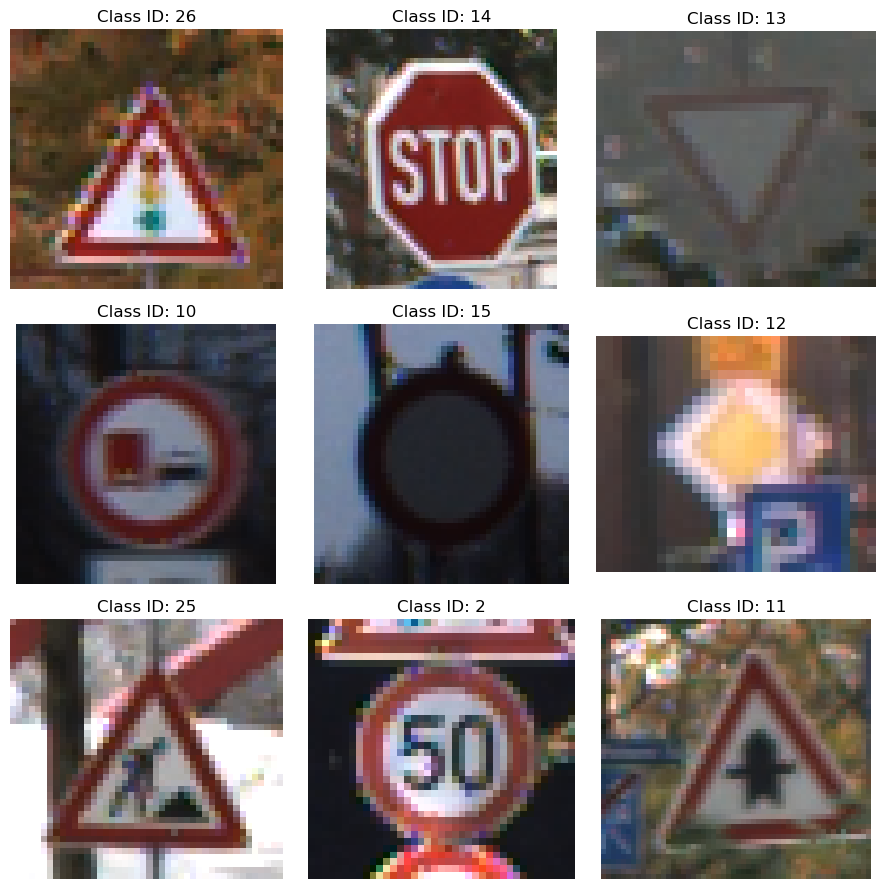

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

samples = train_df.sample(n=9, random_state=42)
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    with Image.open(data_dir / row["Path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"Class ID: {row['ClassId']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Class Names & Distribution

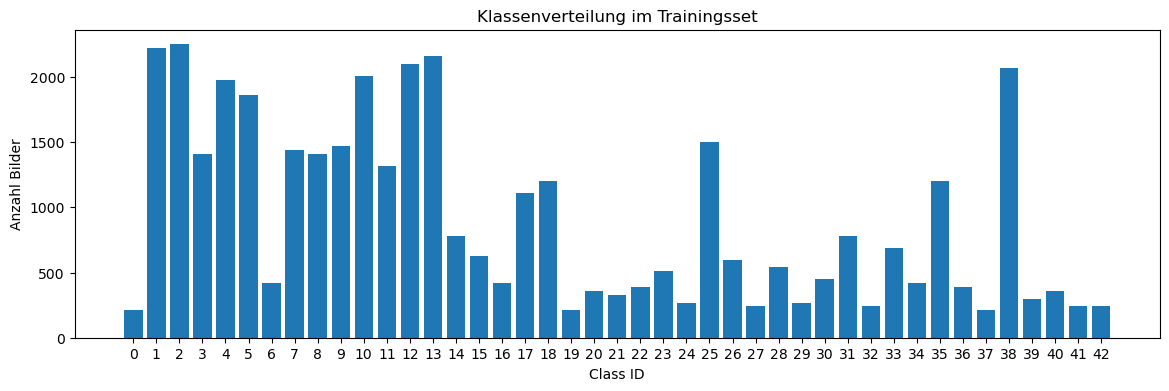

Min: 210 (Klasse 0) | Max: 2250 (Klasse 2)


In [8]:
CLASS_NAMES = [
    "Höchstgeschw. 20 km/h", "Höchstgeschw. 30 km/h", "Höchstgeschw. 50 km/h",
    "Höchstgeschw. 60 km/h", "Höchstgeschw. 70 km/h", "Höchstgeschw. 80 km/h",
    "Ende 80 km/h", "Höchstgeschw. 100 km/h", "Höchstgeschw. 120 km/h",
    "Überholverbot", "Überholverbot Lkw > 3,5 t", "Vorfahrt nächste Kreuzung",
    "Vorfahrtstraße", "Vorfahrt gewähren", "Stopp", "Verbot für Fahrzeuge aller Art",
    "Verbot Lkw > 3,5 t", "Verbot der Einfahrt", "Gefahrenstelle", "Kurve links",
    "Kurve rechts", "Doppelkurve", "Unebene Fahrbahn", "Schleudergefahr",
    "Verengung rechts", "Baustelle", "Ampel", "Fußgänger", "Kinder", "Radverkehr",
    "Schnee-/Eisglätte", "Wildwechsel", "Ende aller Streckenverbote",
    "Rechts abbiegen", "Links abbiegen", "Geradeaus", "Geradeaus oder rechts",
    "Geradeaus oder links", "Rechts vorbei", "Links vorbei", "Kreisverkehr",
    "Ende Überholverbot", "Ende Überholverbot Lkw > 3,5 t",
]
assert len(CLASS_NAMES) == NUM_CLASSES

counts = train_df["ClassId"].value_counts().sort_index()
plt.figure(figsize=(14, 4))
plt.bar(counts.index, counts.values)
plt.xticks(range(NUM_CLASSES))
plt.xlabel("Class ID"); plt.ylabel("Anzahl Bilder")
plt.title("Klassenverteilung im Trainingsset")
plt.show()
print(f"Min: {counts.min()} (Klasse {counts.idxmin()}) | Max: {counts.max()} (Klasse {counts.idxmax()})")

## 8. Load Images (ROI Crop)

In [9]:
def load_images(df, base_dir, img_size=IMG_SIZE, use_roi=True):
    paths = df["Path"].to_numpy()
    rois = df[["Roi.X1", "Roi.Y1", "Roi.X2", "Roi.Y2"]].to_numpy()
    images = np.empty((len(df), img_size, img_size, 3), dtype=np.uint8)

    for i, (p, box) in enumerate(zip(paths, rois)):
        with Image.open(base_dir / p) as img:
            img = img.convert("RGB")
            if use_roi:
                img = img.crop(tuple(int(v) for v in box))
            images[i] = np.asarray(img.resize((img_size, img_size)))
    return images, df["ClassId"].to_numpy()

X_all, y_all = load_images(train_df, data_dir)
print("X_all:", X_all.shape, X_all.dtype, "| y_all:", y_all.shape)

X_all: (39209, 32, 32, 3) uint8 | y_all: (39209,)


## 9. Train / Validation Split

In [10]:
# Track-ID aus dem Dateinamen: "00020_00000_00001.png" → "00020_00000"
groups = train_df["Path"].str.split("/").str[-1].str.rsplit("_", n=1).str[0].to_numpy()

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (train_idx, val_idx) in enumerate(sgkf.split(X_all, y_all, groups)):
    n_val_classes = len(np.unique(y_all[val_idx]))
    print(f"Fold {fold}: {n_val_classes} Klassen in Val")
    if n_val_classes == NUM_CLASSES:
        break

X_train, X_val = X_all[train_idx], X_all[val_idx]
y_train, y_val = y_all[train_idx], y_all[val_idx]

print("\nGewählter Fold:", fold)
print("Train:", X_train.shape, "| Val:", X_val.shape)
print("Klassen in Val:", len(np.unique(y_val)), "von", NUM_CLASSES)
print("Gemeinsame Tracks:", len(set(groups[train_idx]) & set(groups[val_idx])))

Fold 0: 42 Klassen in Val
Fold 1: 43 Klassen in Val

Gewählter Fold: 1
Train: (31349, 32, 32, 3) | Val: (7860, 32, 32, 3)
Klassen in Val: 43 von 43
Gemeinsame Tracks: 0


## 10. Build CNN Model

In [11]:
def build_model(img_size=IMG_SIZE):
    # Augmentation jetzt INNERHALB der Funktion → jedes Modell bekommt eigene Layer
    data_augmentation = keras.Sequential([
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
    ], name="augmentation")

    inputs = keras.Input(shape=(img_size, img_size, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    for filters in (32, 64, 128):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="traffic_sign_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )
    return model

model = build_model()
model.summary()

I0000 00:00:1793995081.769472   38150 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21242 MB memory:  -> device: 0, name: NVIDIA A40, pci bus id: 0000:00:10.0, compute capability: 8.6


Model: "traffic_sign_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 823,947 (3.14 MB)

 Trainable params: 823,051 (3.14 MB)

 Non-trainable params: 896 (3.50 KB)

## 11. Train Model

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "best_model.keras", monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    callbacks=callbacks,
)

Epoch 1/40


E0000 00:00:1793995086.036872   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
2026-11-06 19:58:07.241607: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1768 - loss: 3.1030
Epoch 1: val_loss improved from None to 1.43170, saving model to best_model.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.2895 - loss: 2.4615 - val_accuracy: 0.5304 - val_loss: 1.4317 - learning_rate: 0.0010
Epoch 2/40
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5802 - loss: 1.2544
Epoch 2: val_loss improved from 1.43170 to 0.36374, saving model to best_model.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6467 - loss: 1.0456 - val_accuracy: 0.8955 - val_loss: 0.3637 - learning_rate: 0.0010
Epoch 3/40
488/490 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7828 - loss: 0.6348
Epoch 3: val_loss improved from 0.36374 to 0.14699, saving model to best_model.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8032 - loss: 0.5735 - val_accuracy: 0.9615 - val_loss: 0.1470 - learning_rate: 0.0010
Epoch 4/40
489/490 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8588

## 12. Training Curves

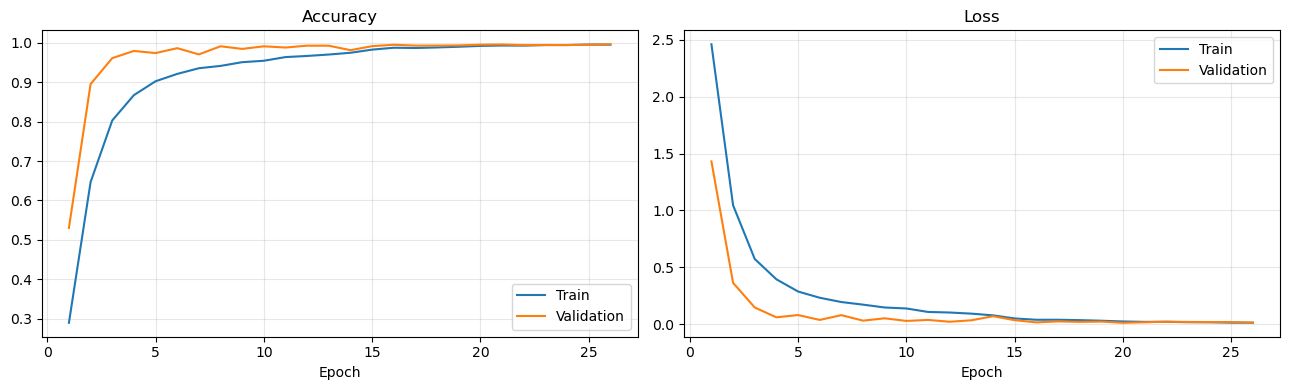

Bester Epoch: 20 | val_loss: 0.0125 | val_accuracy: 0.9955


In [13]:
h = history.history
epochs_range = range(1, len(h["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs_range, h["accuracy"], label="Train")
ax1.plot(epochs_range, h["val_accuracy"], label="Validation")
ax1.set_title("Accuracy"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs_range, h["loss"], label="Train")
ax2.plot(epochs_range, h["val_loss"], label="Validation")
ax2.set_title("Loss"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

best = int(np.argmin(h["val_loss"]))
print(f"Bester Epoch: {best + 1} | val_loss: {h['val_loss'][best]:.4f} | val_accuracy: {h['val_accuracy'][best]:.4f}")

## 13. Evaluate on Test Set

In [14]:
# Test-Bilder genauso laden wie Training (ROI-Crop, 32×32)
X_test, y_test = load_images(test_df, data_dir)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

# Vorhersagen
probs = model.predict(X_test, batch_size=256, verbose=0)
y_pred = probs.argmax(axis=1)

test_acc = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {test_acc:.4f}   (altes Modell: 0.9495)")
print(f"Falsch klassifiziert: {(y_pred != y_test).sum()} von {len(y_test)}\n")

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

X_test: (12630, 32, 32, 3) | y_test: (12630,)

Test Accuracy: 0.9899   (altes Modell: 0.9495)
Falsch klassifiziert: 128 von 12630

                                precision    recall  f1-score   support

         Höchstgeschw. 20 km/h      1.000     1.000     1.000        60
         Höchstgeschw. 30 km/h      0.985     1.000     0.992       720
         Höchstgeschw. 50 km/h      0.999     0.996     0.997       750
         Höchstgeschw. 60 km/h      1.000     0.984     0.992       450
         Höchstgeschw. 70 km/h      1.000     0.998     0.999       660
         Höchstgeschw. 80 km/h      0.983     0.997     0.990       630
                  Ende 80 km/h      1.000     0.980     0.990       150
        Höchstgeschw. 100 km/h      1.000     0.998     0.999       450
        Höchstgeschw. 120 km/h      0.996     0.998     0.997       450
                 Überholverbot      0.994     1.000     0.997       480
     Überholverbot Lkw > 3,5 t      1.000     0.998     0.999       660
    

## 14. Confusion Matrix

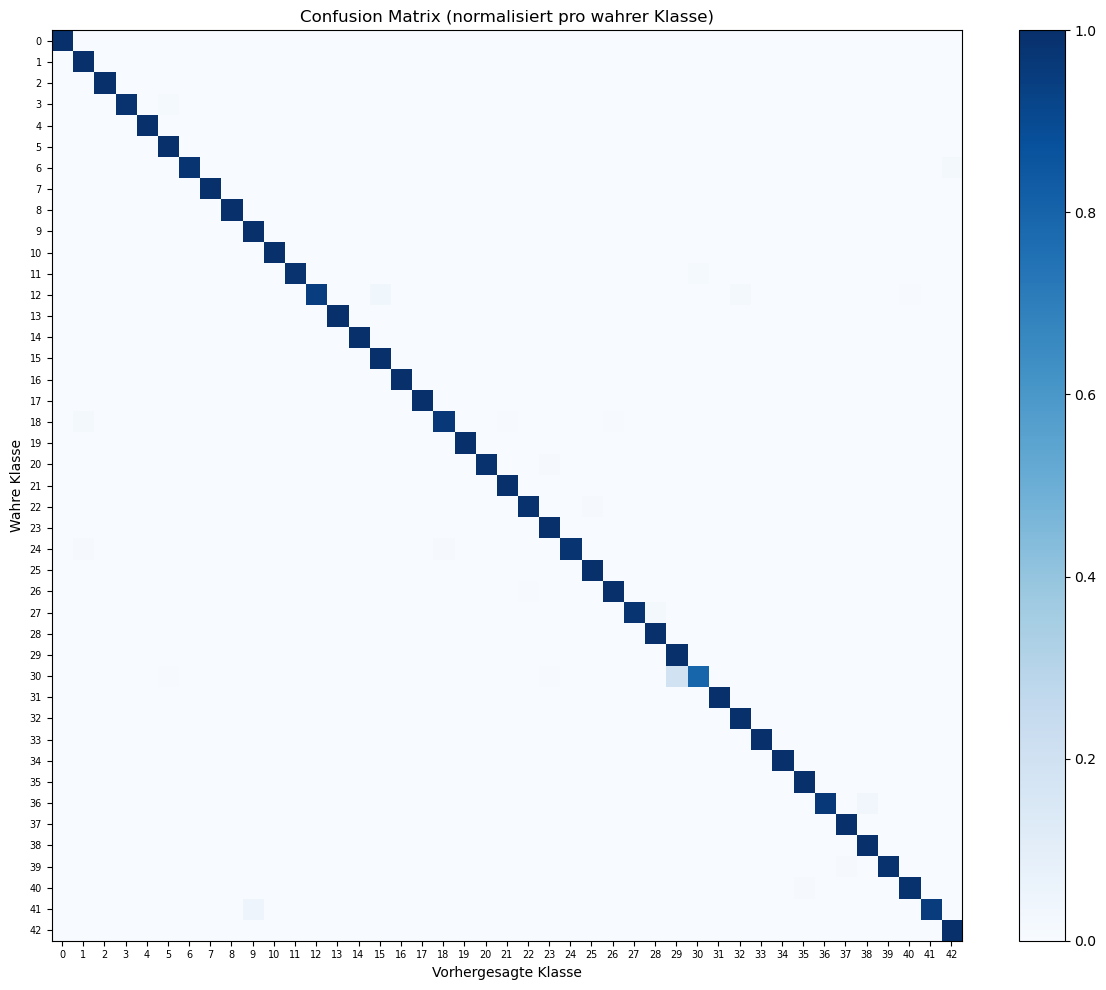

Top-10 Verwechslungen (wahr → vorhergesagt):
  29×  [30] Schnee-/Eisglätte  →  [29] Radverkehr
  25×  [12] Vorfahrtstraße  →  [15] Verbot für Fahrzeuge aller Art
  11×  [12] Vorfahrtstraße  →  [32] Ende aller Streckenverbote
   8×  [18] Gefahrenstelle  →  [ 1] Höchstgeschw. 30 km/h
   7×  [ 3] Höchstgeschw. 60 km/h  →  [ 5] Höchstgeschw. 80 km/h
   6×  [11] Vorfahrt nächste Kreuzung  →  [30] Schnee-/Eisglätte
   4×  [36] Geradeaus oder rechts  →  [38] Rechts vorbei
   4×  [12] Vorfahrtstraße  →  [40] Kreisverkehr
   3×  [41] Ende Überholverbot  →  [ 9] Überholverbot
   3×  [18] Gefahrenstelle  →  [26] Ampel


In [15]:
cm = confusion_matrix(y_test, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.tick_params(labelsize=7)
ax.set_xlabel("Vorhergesagte Klasse"); ax.set_ylabel("Wahre Klasse")
ax.set_title("Confusion Matrix (normalisiert pro wahrer Klasse)")
fig.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

# Häufigste Verwechslungen als Liste
cm_counts = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm_counts, 0)
pairs = [(cm_counts[i, j], i, j)
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_counts[i, j] > 0]

print("Top-10 Verwechslungen (wahr → vorhergesagt):")
for n, i, j in sorted(pairs, reverse=True)[:10]:
    print(f"{n:4d}×  [{i:2d}] {CLASS_NAMES[i]}  →  [{j:2d}] {CLASS_NAMES[j]}")

## 15. Inspect Top Confusions

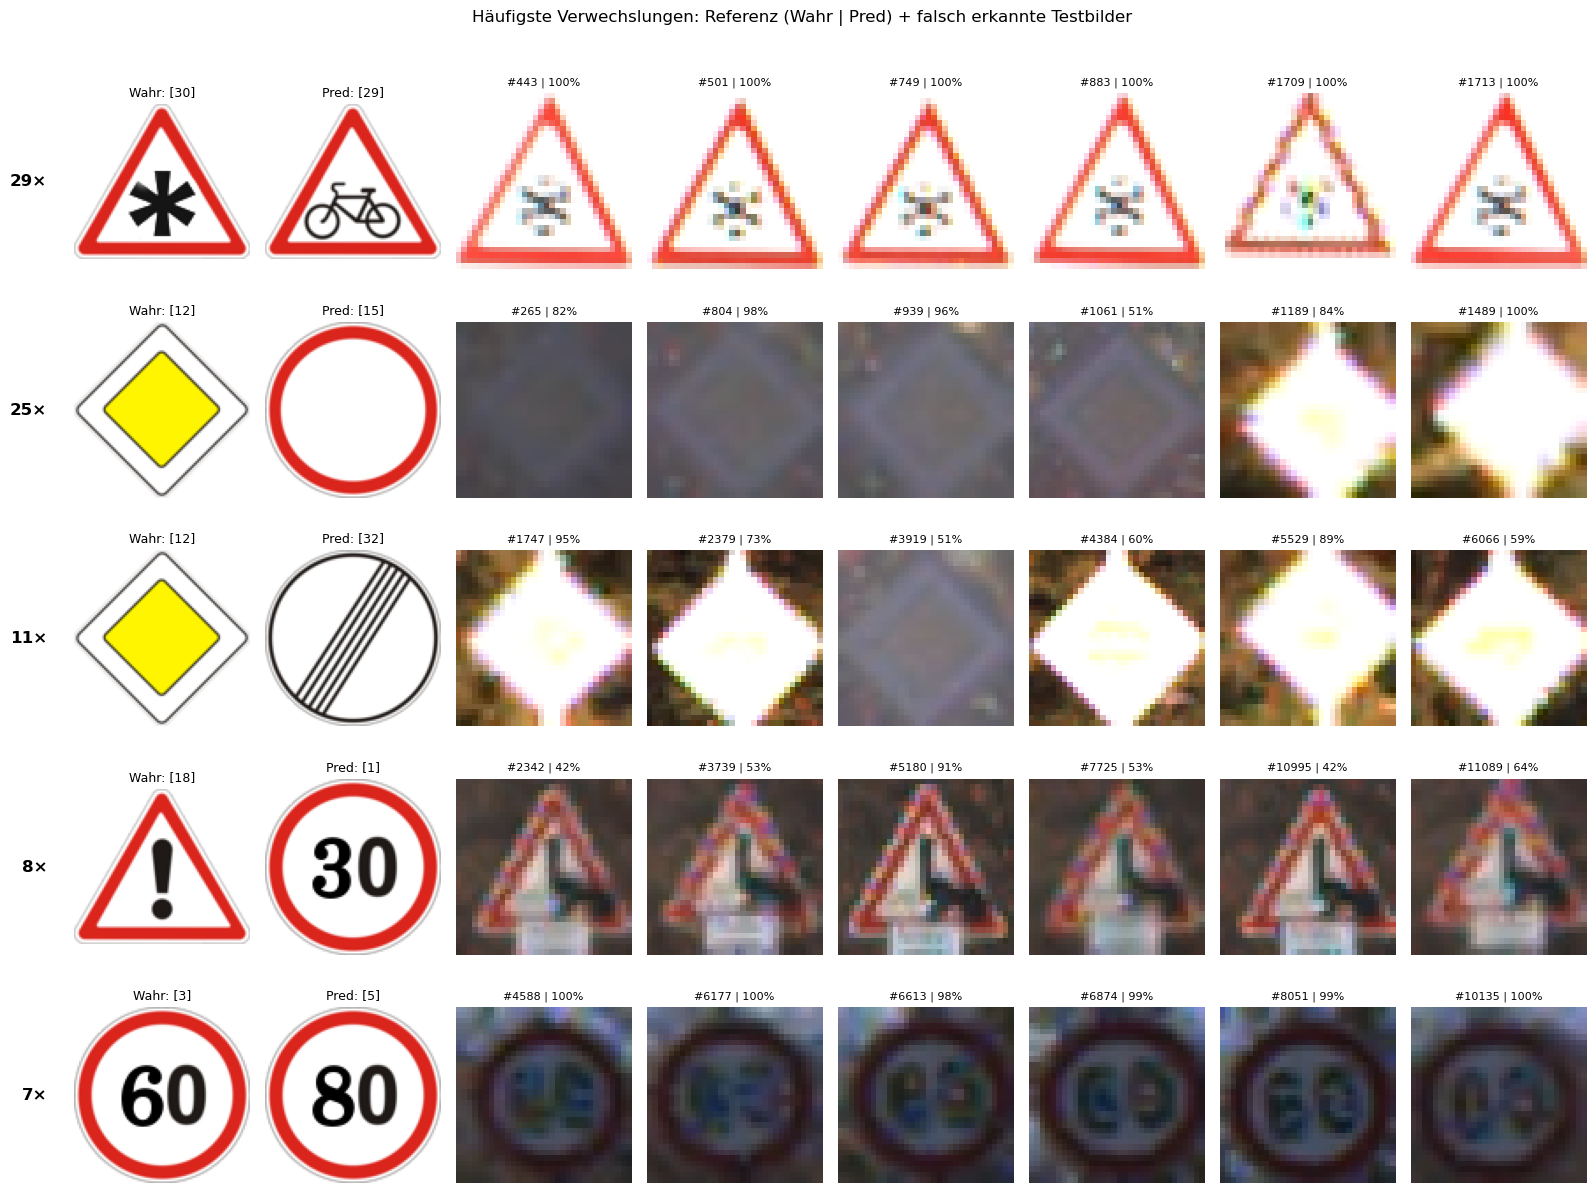

In [16]:
top_pairs = sorted(pairs, reverse=True)[:5]
n_show = 6

fig, axes = plt.subplots(len(top_pairs), n_show + 2,
                         figsize=(2 * (n_show + 2), 2.4 * len(top_pairs)))

for r, (n, i, j) in enumerate(top_pairs):
    # Spalte 0–1: offizielle Referenzbilder aus dem Meta-Ordner
    for c, cls, label in [(0, i, "Wahr"), (1, j, "Pred")]:
        with Image.open(data_dir / "Meta" / f"{cls}.png") as ref:
            axes[r, c].imshow(ref.convert("RGBA"))
        axes[r, c].set_title(f"{label}: [{cls}]", fontsize=9)

    # Spalte 2+: falsch klassifizierte Testbilder (so wie das Modell sie sieht: 32×32)
    idx = np.where((y_test == i) & (y_pred == j))[0][:n_show]
    for c, k in enumerate(idx):
        axes[r, c + 2].imshow(X_test[k])
        axes[r, c + 2].set_title(f"#{k} | {probs[k, j]:.0%}", fontsize=8)

    for ax in axes[r]:
        ax.axis("off")
    axes[r, 0].text(-0.15, 0.5, f"{n}×", transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=12, fontweight="bold")

plt.suptitle("Häufigste Verwechslungen: Referenz (Wahr | Pred) + falsch erkannte Testbilder", y=1.01)
plt.tight_layout()
plt.show()

## 16. Save Baseline

In [17]:
model.save("model_baseline.keras")
results = {"Baseline (ROI, 32px)": test_acc}
print(results)

{'Baseline (ROI, 32px)': 0.9898653998416469}


## 17. Preview: Luminance Equalization

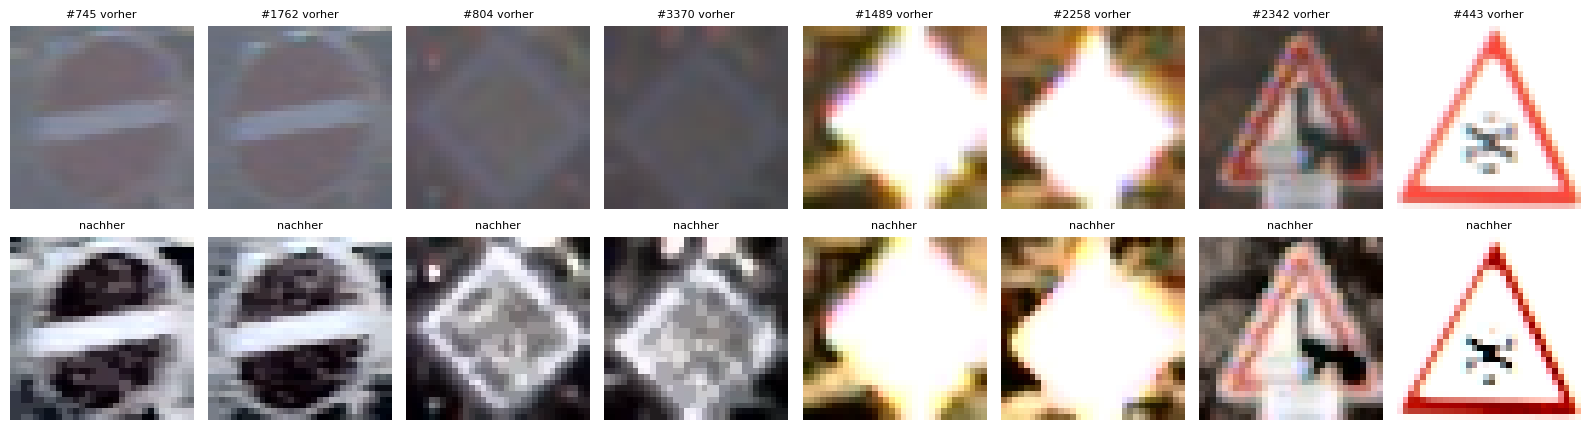

In [18]:
from PIL import ImageOps

def equalize_luminance(img):
    """Histogramm-Ausgleich nur auf der Helligkeit (Y), Farben (Cb, Cr) bleiben erhalten."""
    y, cb, cr = img.convert("YCbCr").split()
    y = ImageOps.equalize(y)
    return Image.merge("YCbCr", (y, cb, cr)).convert("RGB")

problem_ids = [745, 1762, 804, 3370, 1489, 2258, 2342, 443]

fig, axes = plt.subplots(2, len(problem_ids), figsize=(2 * len(problem_ids), 4.5))
for c, k in enumerate(problem_ids):
    before = Image.fromarray(X_test[k])
    after = equalize_luminance(before)
    axes[0, c].imshow(before); axes[0, c].set_title(f"#{k} vorher", fontsize=8)
    axes[1, c].imshow(after);  axes[1, c].set_title("nachher", fontsize=8)
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout()
plt.show()

## 18. Experiment Helper

In [19]:
def run_experiment(name, X_tr, y_tr, X_va, y_va, X_te, y_te, model_fn=build_model, seed=SEED):
    keras.backend.clear_session()          # alten Graph/Speicher freigeben
    keras.utils.set_random_seed(SEED)      # gleiche Startbedingungen für jeden Versuch

    m = model_fn()
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
        keras.callbacks.ModelCheckpoint(f"best_{name}.keras", monitor="val_loss", save_best_only=True),
    ]
    h = m.fit(X_tr, y_tr, validation_data=(X_va, y_va),
              epochs=40, batch_size=64, callbacks=cbs, verbose=2)

    p = m.predict(X_te, batch_size=256, verbose=0)
    yp = p.argmax(axis=1)
    acc = accuracy_score(y_te, yp)
    results[name] = acc

    best = int(np.argmin(h.history["val_loss"]))
    print(f"\n[{name}] Bester Epoch: {best + 1} | val_acc: {h.history['val_accuracy'][best]:.4f}"
          f" | Test Accuracy: {acc:.4f} | Fehler: {(yp != y_te).sum()}")
    return m, h, p, yp

## 19. Experiment A: Luminance Equalization

In [20]:
def equalize_array(X):
    return np.stack([np.asarray(equalize_luminance(Image.fromarray(x))) for x in X])

X_all_eq  = equalize_array(X_all)
X_test_eq = equalize_array(X_test)

# Gleicher Split wie Baseline (train_idx / val_idx aus Schritt 9)
X_train_eq, X_val_eq = X_all_eq[train_idx], X_all_eq[val_idx]

model_A, hist_A, probs_A, pred_A = run_experiment(
    "A_equalize", X_train_eq, y_train, X_val_eq, y_val, X_test_eq, y_test
)
print(results)

Epoch 1/40


E0000 00:00:1793995248.467652   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 9s - 18ms/step - accuracy: 0.3908 - loss: 2.1035 - val_accuracy: 0.7700 - val_loss: 0.7339 - learning_rate: 0.0010
Epoch 2/40
490/490 - 5s - 11ms/step - accuracy: 0.7187 - loss: 0.8492 - val_accuracy: 0.8955 - val_loss: 0.2766 - learning_rate: 0.0010
Epoch 3/40
490/490 - 5s - 11ms/step - accuracy: 0.8158 - loss: 0.5476 - val_accuracy: 0.9354 - val_loss: 0.1917 - learning_rate: 0.0010
Epoch 4/40
490/490 - 5s - 11ms/step - accuracy: 0.8582 - loss: 0.4238 - val_accuracy: 0.9650 - val_loss: 0.1080 - learning_rate: 0.0010
Epoch 5/40
490/490 - 5s - 11ms/step - accuracy: 0.8848 - loss: 0.3415 - val_accuracy: 0.9430 - val_loss: 0.1666 - learning_rate: 0.0010
Epoch 6/40
490/490 - 5s - 11ms/step - accuracy: 0.9092 - loss: 0.2741 - val_accuracy: 0.9734 - val_loss: 0.0845 - learning_rate: 0.0010
Epoch 7/40
490/490 - 5s - 11ms/step - accuracy: 0.9241 - loss: 0.2267 - val_accuracy: 0.9779 - val_loss: 0.0762 - learning_rate: 0.0010
Epoch 8/40
490/490 - 5s - 11ms/step - accuracy: 0.9332 - lo

## 20. Compare Baseline vs. A

In [21]:
from sklearn.metrics import recall_score

wrong_base = y_pred != y_test
wrong_A    = pred_A != y_test
print(f"Fehler Baseline: {wrong_base.sum()} | Fehler A: {wrong_A.sum()}")
print(f"  → von A korrigiert:     {(wrong_base & ~wrong_A).sum()}")
print(f"  → neu falsch durch A:   {(~wrong_base & wrong_A).sum()}")
print(f"  → in beiden falsch:     {(wrong_base & wrong_A).sum()}")

# Recall pro Klasse vergleichen
rec_base = recall_score(y_test, y_pred, average=None)
rec_A    = recall_score(y_test, pred_A, average=None)
diff = rec_A - rec_base
order = np.argsort(diff)

print("\nGrößte Verschlechterungen durch A (Recall):")
for c in order[:5]:
    print(f"  [{c:2d}] {CLASS_NAMES[c]:32s} {rec_base[c]:.3f} → {rec_A[c]:.3f}  ({diff[c]:+.3f})")

print("\nGrößte Verbesserungen durch A (Recall):")
for c in order[::-1][:5]:
    print(f"  [{c:2d}] {CLASS_NAMES[c]:32s} {rec_base[c]:.3f} → {rec_A[c]:.3f}  ({diff[c]:+.3f})")

# Die Problem-Bilder aus Schritt 17
print("\nProblem-Bilder:")
for k in problem_ids:
    ok_b = "✓" if y_pred[k] == y_test[k] else "✗"
    ok_a = "✓" if pred_A[k] == y_test[k] else "✗"
    print(f"  #{k:5d} wahr: {CLASS_NAMES[y_test[k]]:26s} | Baseline {ok_b} {CLASS_NAMES[y_pred[k]]:26s} | A {ok_a} {CLASS_NAMES[pred_A[k]]}")

Fehler Baseline: 128 | Fehler A: 153
  → von A korrigiert:     89
  → neu falsch durch A:   114
  → in beiden falsch:     39

Größte Verschlechterungen durch A (Recall):
  [ 5] Höchstgeschw. 80 km/h            0.997 → 0.951  (-0.046)
  [11] Vorfahrt nächste Kreuzung        0.986 → 0.943  (-0.043)
  [23] Schleudergefahr                  1.000 → 0.960  (-0.040)
  [15] Verbot für Fahrzeuge aller Art   1.000 → 0.962  (-0.038)
  [41] Ende Überholverbot               0.950 → 0.917  (-0.033)

Größte Verbesserungen durch A (Recall):
  [30] Schnee-/Eisglätte                0.793 → 0.993  (+0.200)
  [12] Vorfahrtstraße                   0.942 → 0.984  (+0.042)
  [36] Geradeaus oder rechts            0.967 → 1.000  (+0.033)
  [27] Fußgänger                        0.983 → 1.000  (+0.017)
  [24] Verengung rechts                 0.978 → 0.989  (+0.011)

Problem-Bilder:
  #  745 wahr: Verbot der Einfahrt        | Baseline ✓ Verbot der Einfahrt        | A ✓ Verbot der Einfahrt
  # 1762 wahr: Verbot de

## 21. Ensemble: Baseline + A

In [22]:
# Baseline-Modell sicher neu laden (clear_session in run_experiment)
model_base = keras.models.load_model("model_baseline.keras")

def ensemble_eval(name, y_true, probs_list):
    p = np.mean(probs_list, axis=0)
    yp = p.argmax(axis=1)
    return accuracy_score(y_true, yp), yp

# 1) Erst auf Validation prüfen (faire Entscheidung, ohne Test-Set)
pv_base = model_base.predict(X_val, batch_size=256, verbose=0)
pv_A    = model_A.predict(X_val_eq, batch_size=256, verbose=0)
for name, pl in [("Baseline", [pv_base]), ("A", [pv_A]), ("Ensemble", [pv_base, pv_A])]:
    acc, yp = ensemble_eval(name, y_val, pl)
    print(f"Val  {name:9s}: {acc:.4f}  (Fehler: {(yp != y_val).sum()})")

# 2) Dann auf Test
acc_ens, pred_ens = ensemble_eval("Ensemble", y_test, [probs, probs_A])
results["Ensemble (Baseline + A)"] = acc_ens
print(f"\nTest Ensemble: {acc_ens:.4f}  (Fehler: {(pred_ens != y_test).sum()})")

print("\nProblem-Bilder (Ensemble):")
for k in problem_ids:
    ok = "✓" if pred_ens[k] == y_test[k] else "✗"
    print(f"  #{k:5d} {CLASS_NAMES[y_test[k]]:26s} → {ok} {CLASS_NAMES[pred_ens[k]]}")

print("\n", {k: round(v, 4) for k, v in results.items()})

Val  Baseline : 0.9955  (Fehler: 35)
Val  A        : 0.9957  (Fehler: 34)
Val  Ensemble : 0.9981  (Fehler: 15)

Test Ensemble: 0.9940  (Fehler: 76)

Problem-Bilder (Ensemble):
  #  745 Verbot der Einfahrt        → ✓ Verbot der Einfahrt
  # 1762 Verbot der Einfahrt        → ✓ Verbot der Einfahrt
  #  804 Vorfahrtstraße             → ✓ Vorfahrtstraße
  # 3370 Vorfahrtstraße             → ✗ Kreisverkehr
  # 1489 Vorfahrtstraße             → ✗ Verbot für Fahrzeuge aller Art
  # 2258 Vorfahrtstraße             → ✗ Verbot für Fahrzeuge aller Art
  # 2342 Gefahrenstelle             → ✓ Gefahrenstelle
  #  443 Schnee-/Eisglätte          → ✗ Radverkehr

 {'Baseline (ROI, 32px)': 0.9899, 'A_equalize': 0.9879, 'Ensemble (Baseline + A)': 0.994}


## 22. Control: Ensemble with a Second Baseline

In [23]:
# Gleiche Daten wie Baseline, nur anderer Seed
model_B7, hist_B7, probs_B7, pred_B7 = run_experiment(
    "Baseline_seed7", X_train, y_train, X_val, y_val, X_test, y_test, seed=7
)

pv_B7 = model_B7.predict(X_val, batch_size=256, verbose=0)

print("\nValidation:")
for name, pl in [("Baseline + Baseline(seed7)", [pv_base, pv_B7]),
                 ("Baseline + A",               [pv_base, pv_A])]:
    acc, yp = ensemble_eval(name, y_val, pl)
    print(f"  {name:28s}: {acc:.4f}  (Fehler: {(yp != y_val).sum()})")

acc_ctrl, pred_ctrl = ensemble_eval("ctrl", y_test, [probs, probs_B7])
results["Ensemble (Baseline + Baseline seed7)"] = acc_ctrl

print("\nTest:")
print(f"  Baseline + Baseline(seed7) : {acc_ctrl:.4f}  (Fehler: {(pred_ctrl != y_test).sum()})")
print(f"  Baseline + A               : {acc_ens:.4f}  (Fehler: {(pred_ens != y_test).sum()})")

Epoch 1/40


E0000 00:00:1793995402.059093   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 9s - 18ms/step - accuracy: 0.3106 - loss: 2.4566 - val_accuracy: 0.5463 - val_loss: 1.4231 - learning_rate: 0.0010
Epoch 2/40
490/490 - 5s - 11ms/step - accuracy: 0.6405 - loss: 1.0667 - val_accuracy: 0.8648 - val_loss: 0.3645 - learning_rate: 0.0010
Epoch 3/40
490/490 - 5s - 11ms/step - accuracy: 0.7972 - loss: 0.5844 - val_accuracy: 0.9369 - val_loss: 0.1697 - learning_rate: 0.0010
Epoch 4/40
490/490 - 5s - 11ms/step - accuracy: 0.8617 - loss: 0.4077 - val_accuracy: 0.9716 - val_loss: 0.0877 - learning_rate: 0.0010
Epoch 5/40
490/490 - 5s - 11ms/step - accuracy: 0.8953 - loss: 0.3056 - val_accuracy: 0.9836 - val_loss: 0.0523 - learning_rate: 0.0010
Epoch 6/40
490/490 - 5s - 11ms/step - accuracy: 0.9208 - loss: 0.2360 - val_accuracy: 0.9896 - val_loss: 0.0410 - learning_rate: 0.0010
Epoch 7/40
490/490 - 5s - 11ms/step - accuracy: 0.9384 - loss: 0.1910 - val_accuracy: 0.9841 - val_loss: 0.0532 - learning_rate: 0.0010
Epoch 8/40
490/490 - 5s - 11ms/step - accuracy: 0.9497 - lo

## 23. Multi-Seed Evaluation (Baseline vs. A)

In [24]:
SEEDS = [42, 7, 123]

# Bereits vorhandene Läufe wiederverwenden (Test-Wahrscheinlichkeiten)
runs = {
    ("Baseline", 42): probs,
    ("Baseline", 7):  probs_B7,
    ("A", 42):        probs_A,
}

# Fehlende Läufe trainieren
for seed in SEEDS:
    if ("Baseline", seed) not in runs:
        _, _, p, _ = run_experiment(f"Baseline_seed{seed}", X_train, y_train, X_val, y_val,
                                    X_test, y_test, seed=seed)
        runs[("Baseline", seed)] = p
    if ("A", seed) not in runs:
        _, _, p, _ = run_experiment(f"A_seed{seed}", X_train_eq, y_train, X_val_eq, y_val,
                                    X_test_eq, y_test, seed=seed)
        runs[("A", seed)] = p

print("Vorhandene Läufe:", sorted(runs.keys()))

Epoch 1/40


E0000 00:00:1793995533.981459   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 9s - 17ms/step - accuracy: 0.3824 - loss: 2.1595 - val_accuracy: 0.7875 - val_loss: 0.7356 - learning_rate: 0.0010
Epoch 2/40
490/490 - 5s - 11ms/step - accuracy: 0.7221 - loss: 0.8425 - val_accuracy: 0.8777 - val_loss: 0.3357 - learning_rate: 0.0010
Epoch 3/40
490/490 - 5s - 11ms/step - accuracy: 0.8334 - loss: 0.4980 - val_accuracy: 0.9391 - val_loss: 0.1888 - learning_rate: 0.0010
Epoch 4/40
490/490 - 5s - 11ms/step - accuracy: 0.8845 - loss: 0.3506 - val_accuracy: 0.9784 - val_loss: 0.0747 - learning_rate: 0.0010
Epoch 5/40
490/490 - 5s - 11ms/step - accuracy: 0.9115 - loss: 0.2737 - val_accuracy: 0.9673 - val_loss: 0.0994 - learning_rate: 0.0010
Epoch 6/40
490/490 - 5s - 11ms/step - accuracy: 0.9279 - loss: 0.2244 - val_accuracy: 0.9818 - val_loss: 0.0600 - learning_rate: 0.0010
Epoch 7/40
490/490 - 5s - 11ms/step - accuracy: 0.9413 - loss: 0.1843 - val_accuracy: 0.9775 - val_loss: 0.0687 - learning_rate: 0.0010
Epoch 8/40
490/490 - 5s - 11ms/step - accuracy: 0.9476 - lo

E0000 00:00:1793995748.659257   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 9s - 18ms/step - accuracy: 0.3290 - loss: 2.3593 - val_accuracy: 0.6167 - val_loss: 1.1769 - learning_rate: 0.0010
Epoch 2/40
490/490 - 5s - 11ms/step - accuracy: 0.6802 - loss: 0.9545 - val_accuracy: 0.9256 - val_loss: 0.2500 - learning_rate: 0.0010
Epoch 3/40
490/490 - 5s - 11ms/step - accuracy: 0.8263 - loss: 0.5189 - val_accuracy: 0.9673 - val_loss: 0.1325 - learning_rate: 0.0010
Epoch 4/40
490/490 - 5s - 11ms/step - accuracy: 0.8868 - loss: 0.3369 - val_accuracy: 0.9837 - val_loss: 0.0624 - learning_rate: 0.0010
Epoch 5/40
490/490 - 5s - 10ms/step - accuracy: 0.9149 - loss: 0.2535 - val_accuracy: 0.9810 - val_loss: 0.0577 - learning_rate: 0.0010
Epoch 6/40
490/490 - 5s - 11ms/step - accuracy: 0.9325 - loss: 0.2050 - val_accuracy: 0.9782 - val_loss: 0.0652 - learning_rate: 0.0010
Epoch 7/40
490/490 - 5s - 11ms/step - accuracy: 0.9428 - loss: 0.1774 - val_accuracy: 0.9896 - val_loss: 0.0268 - learning_rate: 0.0010
Epoch 8/40
490/490 - 5s - 11ms/step - accuracy: 0.9491 - lo

E0000 00:00:1793995902.775029   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 8s - 17ms/step - accuracy: 0.3846 - loss: 2.1337 - val_accuracy: 0.7485 - val_loss: 0.9429 - learning_rate: 0.0010
Epoch 2/40
490/490 - 5s - 11ms/step - accuracy: 0.6961 - loss: 0.9116 - val_accuracy: 0.9078 - val_loss: 0.2739 - learning_rate: 0.0010
Epoch 3/40
490/490 - 5s - 10ms/step - accuracy: 0.8082 - loss: 0.5667 - val_accuracy: 0.9375 - val_loss: 0.1797 - learning_rate: 0.0010
Epoch 4/40
490/490 - 5s - 10ms/step - accuracy: 0.8537 - loss: 0.4349 - val_accuracy: 0.9496 - val_loss: 0.1587 - learning_rate: 0.0010
Epoch 5/40
490/490 - 5s - 10ms/step - accuracy: 0.8925 - loss: 0.3265 - val_accuracy: 0.9654 - val_loss: 0.0936 - learning_rate: 0.0010
Epoch 6/40
490/490 - 5s - 10ms/step - accuracy: 0.9188 - loss: 0.2432 - val_accuracy: 0.9775 - val_loss: 0.0773 - learning_rate: 0.0010
Epoch 7/40
490/490 - 5s - 10ms/step - accuracy: 0.9329 - loss: 0.2027 - val_accuracy: 0.9870 - val_loss: 0.0418 - learning_rate: 0.0010
Epoch 8/40
490/490 - 5s - 10ms/step - accuracy: 0.9476 - lo

## 24. Multi-Seed Summary

In [25]:
def test_acc_of(p):
    return accuracy_score(y_test, p.argmax(axis=1))

rows = {
    "Baseline":                 [test_acc_of(runs[("Baseline", s)]) for s in SEEDS],
    "A (Equalize)":             [test_acc_of(runs[("A", s)]) for s in SEEDS],
    "Ensemble Baseline + A":    [test_acc_of((runs[("Baseline", s)] + runs[("A", s)]) / 2) for s in SEEDS],
    "Ensemble Baseline + Base": [test_acc_of((runs[("Baseline", a)] + runs[("Baseline", b)]) / 2)
                                 for a, b in [(42, 7), (7, 123), (123, 42)]],
}

print(f"{'Methode':28s} {'Mittelwert ± Std':>18s}   Einzelläufe")
for name, accs in rows.items():
    accs = np.array(accs) * 100
    print(f"{name:28s} {accs.mean():7.2f} ± {accs.std(ddof=1):.2f} %   "
          + "  ".join(f"{a:.2f}" for a in accs))

Methode                        Mittelwert ± Std   Einzelläufe
Baseline                       98.99 ± 0.02 %   98.99  98.97  99.01
A (Equalize)                   98.98 ± 0.18 %   98.79  99.00  99.14
Ensemble Baseline + A          99.49 ± 0.09 %   99.40  99.50  99.58
Ensemble Baseline + Base       99.17 ± 0.08 %   99.15  99.11  99.26


## 25. Experiment C: 48×48 px

In [26]:
IMG_C = 48

# Bilder in 48×48 neu laden (ROI-Crop wie vorher)
X_all48, _  = load_images(train_df, data_dir, img_size=IMG_C)
X_test48, _ = load_images(test_df,  data_dir, img_size=IMG_C)
X_train48, X_val48 = X_all48[train_idx], X_all48[val_idx]   # gleicher Split
print("Train:", X_train48.shape, "| Val:", X_val48.shape, "| Test:", X_test48.shape)

for seed in SEEDS:
    if ("C48", seed) not in runs:
        _, _, p, _ = run_experiment(
            f"C48_seed{seed}", X_train48, y_train, X_val48, y_val, X_test48, y_test,
            model_fn=lambda: build_model(IMG_C), seed=seed,
        )
        runs[("C48", seed)] = p

c48 = np.array([test_acc_of(runs[("C48", s)]) for s in SEEDS]) * 100
print(f"\nC (48px): {c48.mean():.2f} ± {c48.std(ddof=1):.2f} %   "
      + "  ".join(f"{a:.2f}" for a in c48))

Train: (31349, 48, 48, 3) | Val: (7860, 48, 48, 3) | Test: (12630, 48, 48, 3)
Epoch 1/40


E0000 00:00:1793996140.486378   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 11s - 23ms/step - accuracy: 0.2330 - loss: 2.6829 - val_accuracy: 0.4532 - val_loss: 1.6418 - learning_rate: 0.0010
Epoch 2/40
490/490 - 7s - 14ms/step - accuracy: 0.3963 - loss: 1.7860 - val_accuracy: 0.7289 - val_loss: 0.8752 - learning_rate: 0.0010
Epoch 3/40
490/490 - 7s - 14ms/step - accuracy: 0.4867 - loss: 1.4600 - val_accuracy: 0.8125 - val_loss: 0.5688 - learning_rate: 0.0010
Epoch 4/40
490/490 - 7s - 14ms/step - accuracy: 0.5417 - loss: 1.2922 - val_accuracy: 0.8440 - val_loss: 0.4393 - learning_rate: 0.0010
Epoch 5/40
490/490 - 7s - 14ms/step - accuracy: 0.5826 - loss: 1.1750 - val_accuracy: 0.8788 - val_loss: 0.4187 - learning_rate: 0.0010
Epoch 6/40
490/490 - 7s - 14ms/step - accuracy: 0.6118 - loss: 1.0780 - val_accuracy: 0.9008 - val_loss: 0.2911 - learning_rate: 0.0010
Epoch 7/40
490/490 - 7s - 14ms/step - accuracy: 0.6303 - loss: 1.0153 - val_accuracy: 0.9004 - val_loss: 0.2853 - learning_rate: 0.0010
Epoch 8/40
490/490 - 7s - 14ms/step - accuracy: 0.6483 - l

E0000 00:00:1793996345.695795   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 10s - 21ms/step - accuracy: 0.2392 - loss: 2.6665 - val_accuracy: 0.4464 - val_loss: 1.6579 - learning_rate: 0.0010
Epoch 2/40
490/490 - 7s - 14ms/step - accuracy: 0.4272 - loss: 1.7035 - val_accuracy: 0.7431 - val_loss: 0.8265 - learning_rate: 0.0010
Epoch 3/40
490/490 - 7s - 14ms/step - accuracy: 0.5563 - loss: 1.2810 - val_accuracy: 0.8506 - val_loss: 0.4542 - learning_rate: 0.0010
Epoch 4/40
490/490 - 7s - 14ms/step - accuracy: 0.6157 - loss: 1.1011 - val_accuracy: 0.8840 - val_loss: 0.3683 - learning_rate: 0.0010
Epoch 5/40
490/490 - 7s - 14ms/step - accuracy: 0.6641 - loss: 0.9567 - val_accuracy: 0.9081 - val_loss: 0.2532 - learning_rate: 0.0010
Epoch 6/40
490/490 - 7s - 14ms/step - accuracy: 0.7021 - loss: 0.8520 - val_accuracy: 0.9327 - val_loss: 0.2268 - learning_rate: 0.0010
Epoch 7/40
490/490 - 7s - 14ms/step - accuracy: 0.7228 - loss: 0.7891 - val_accuracy: 0.9494 - val_loss: 0.1685 - learning_rate: 0.0010
Epoch 8/40
490/490 - 7s - 14ms/step - accuracy: 0.7572 - l

E0000 00:00:1793996612.318035   38150 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/traffic_sign_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


490/490 - 10s - 21ms/step - accuracy: 0.2401 - loss: 2.6725 - val_accuracy: 0.4383 - val_loss: 1.7547 - learning_rate: 0.0010
Epoch 2/40
490/490 - 7s - 15ms/step - accuracy: 0.4244 - loss: 1.7038 - val_accuracy: 0.7721 - val_loss: 0.7399 - learning_rate: 0.0010
Epoch 3/40
490/490 - 7s - 15ms/step - accuracy: 0.5320 - loss: 1.3416 - val_accuracy: 0.8626 - val_loss: 0.4130 - learning_rate: 0.0010
Epoch 4/40
490/490 - 7s - 14ms/step - accuracy: 0.6053 - loss: 1.1194 - val_accuracy: 0.9221 - val_loss: 0.2675 - learning_rate: 0.0010
Epoch 5/40
490/490 - 7s - 14ms/step - accuracy: 0.6479 - loss: 1.0044 - val_accuracy: 0.9246 - val_loss: 0.3310 - learning_rate: 0.0010
Epoch 6/40
490/490 - 7s - 14ms/step - accuracy: 0.6708 - loss: 0.9288 - val_accuracy: 0.9583 - val_loss: 0.1704 - learning_rate: 0.0010
Epoch 7/40
490/490 - 7s - 14ms/step - accuracy: 0.6990 - loss: 0.8536 - val_accuracy: 0.9690 - val_loss: 0.1532 - learning_rate: 0.0010
Epoch 8/40
490/490 - 7s - 14ms/step - accuracy: 0.7304 - l

## 26. Final Summary (alle Experimente)

In [27]:
from sklearn.metrics import recall_score
SCHNEE = 30
R = lambda m, s: runs[(m, s)]
seed_pairs = [(42, 7), (7, 123), (123, 42)]

methods = {
    "Baseline (32px)":           [R("Baseline", s) for s in SEEDS],
    "A: Equalize (32px)":        [R("A", s) for s in SEEDS],
    "C: 48px":                   [R("C48", s) for s in SEEDS],
    "Ens. Baseline + Baseline":  [(R("Baseline", a) + R("Baseline", b)) / 2 for a, b in seed_pairs],
    "Ens. Baseline + A":         [(R("Baseline", s) + R("A", s)) / 2 for s in SEEDS],
    "Ens. Baseline + C48":       [(R("Baseline", s) + R("C48", s)) / 2 for s in SEEDS],
    "Ens. A + C48":              [(R("A", s) + R("C48", s)) / 2 for s in SEEDS],
    "Ens. Baseline + A + C48":   [(R("Baseline", s) + R("A", s) + R("C48", s)) / 3 for s in SEEDS],
}

rows = []
for name, prob_list in methods.items():
    preds = [p.argmax(axis=1) for p in prob_list]
    accs  = np.array([accuracy_score(y_test, yp) for yp in preds]) * 100
    errs  = np.array([(yp != y_test).sum() for yp in preds])
    rec_s = np.array([recall_score(y_test, yp, labels=[SCHNEE], average=None)[0] for yp in preds]) * 100
    rows.append([name, accs.mean(), accs.std(ddof=1), errs.mean(), rec_s.mean()])

summary = pd.DataFrame(rows, columns=["Methode", "Test-Acc Ø (%)", "Std (%)", "Fehler Ø", "Recall Schnee Ø (%)"])

# Altes Modell als Referenz (1 Lauf, ohne ROI, zufälliger Split)
old = pd.DataFrame([["Altes Modell (Notebook v1)", 94.95, np.nan, 638, np.nan]], columns=summary.columns)
summary = pd.concat([old, summary], ignore_index=True).round(2)

display(summary)
summary.to_csv("results_summary.csv", index=False)
print("Gespeichert: results_summary.csv")

,Methode,Test-Acc Ø (%),Std (%),Fehler Ø,Recall Schnee Ø (%)
0,Altes Modell (Notebook v1),94.95,NaN,638.00,NaN
1,Baseline (32px),98.99,0.02,127.67,85.78
2,A: Equalize (32px),98.98,0.18,129.00,98.44
3,C: 48px,98.85,0.17,145.33,91.56
4,Ens. Baseline + Baseline,99.17,0.08,104.67,84.00
5,Ens. Baseline + A,99.49,0.09,64.00,97.33
6,Ens. Baseline + C48,99.22,0.18,98.33,89.56
7,Ens. A + C48,99.41,0.06,74.00,99.11
8,Ens. Baseline + A + C48,99.46,0.05,68.67,94.44


Gespeichert: results_summary.csv
